# Aula 3 — Detecção de áudio falso: análise exploratória

**Objetivo:** conhecer o subconjunto local do ASVspoof 5, ouvir exemplos e investigar atributos acústicos que possam ajudar a distinguir `bonafide` (legítimo) de `spoof` (falso).

Utilizei a biblioteca de processamento de audio **Librosa**, em vez do PyAudioAnalysis. Ela transforma o áudio em medidas numéricas e representações como espectrogramas e MFCCs.

Este notebook cobre preparação, processamento e exploração. Treinamento e avaliação de classificadores estarão num outro notebook.

## Como executar

Abra este arquivo no Jupyter ou VS Code, selecione o Python de `.venv` do projeto e execute as células em ordem. No terminal PowerShell, na raiz do repositório, as dependências podem ser instaladas com:

```powershell
.\.venv\Scripts\python.exe -m pip install -r outros/aula-03-deteccao-audio-falso/requirements.txt
```

As saídas da execução ficam neste notebook; tabelas e figuras também são salvas no projeto. **Anotações** contem as minhas interpretações e análises de cada etapa.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
from datetime import datetime, timezone
from importlib.metadata import version

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Audio, display, Markdown

# Funciona abrindo o Jupyter na raiz ou em notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'outros/aula-03-deteccao-audio-falso/dados/subconjunto_288').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Abra o notebook a partir de uma pasta dentro do repositório.')

CONFIG = {
    'seed': 42,
    'sr': 16000,            # taxa comum de análise; reamostrar apenas se necessário
    'n_fft': 512,           # janela de 32 ms a 16 kHz
    'hop_length': 160,      # passo de 10 ms
    'n_mels': 64,
    'n_mfcc': 20,
    'silence_dbfs': -40,    # limiar absoluto, exploratório, sobre RMS por janela
    'bonafide_id': None,    # preencha um file_id do TREINO para trocar o exemplo
    'spoof_id': None,
}
DATA = ROOT / 'outros/aula-03-deteccao-audio-falso/dados/subconjunto_288'
OUT = ROOT / 'outros/aula-03-deteccao-audio-falso/resultados/eda'
FIG = ROOT / 'images/aula-03/eda'
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
ORDER = ['bonafide', 'spoof']
PALETTE = {'bonafide': '#237a57', 'spoof': '#c05640'}
sns.set_theme(style='whitegrid', context='notebook', palette=list(PALETTE.values()))
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def salvar_figura(fig, nome):
    fig.savefig(FIG / f'{nome}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Python:', sys.executable)
print('Raiz:', ROOT)
print('Librosa:', librosa.__version__)

Python: d:\Code\portfolio-pcs5917\.venv\Scripts\python.exe
Raiz: d:\Code\portfolio-pcs5917
Librosa: 0.11.0


## 1. Conferir a seleção e preservar o teste

Selecionei 192 áudios de treino e 96 de teste, com classes balanceadas. `role` define o uso neste experimento; `split` mantém a origem oficial (`train`/`dev`). O `dev` oficial foi reservado como **teste final**, com ataques diferentes dos do treino.

Aqui é conferida integridade e metadados das duas partes, mas todas as escutas, estatísticas acústicas e visualizações abaixo usam **somente treino**. Isso permite investigar atributos sem escolher modelos ou parâmetros olhando o teste. IDs, gênero, ataque e caminhos servem para auditoria, não como entradas do futuro classificador.

**Como ler as duas tabelas abaixo:** a primeira resume a quantidade de áudios por classe e partição. A segunda é apenas uma prévia das **cinco primeiras linhas dos metadados de treino** (`head()`), para conferir se o CSV foi lido corretamente.

In [2]:
train = pd.read_csv(DATA / 'treino_192.csv', keep_default_na=False)
test = pd.read_csv(DATA / 'teste_96.csv', keep_default_na=False)
meta = pd.concat([train, test], ignore_index=True)
assert len(train) == 192 and len(test) == 96
assert set(train['role']) == {'train'} and set(test['role']) == {'test'}
assert set(train['split']) == {'train'} and set(test['split']) == {'dev'}
assert set(meta['label']) == set(ORDER)
assert train['label'].value_counts().to_dict() == {'bonafide': 96, 'spoof': 96}
assert test['label'].value_counts().to_dict() == {'bonafide': 48, 'spoof': 48}
assert meta['file_id'].is_unique
assert not set(train['speaker_id']) & set(test['speaker_id']), 'Locutor compartilhado!'
assert meta['speaker_id'].is_unique, 'A seleção esperada tem um áudio por locutor.'
assert not (set(train.loc[train.label == 'spoof', 'attack']) &
            set(test.loc[test.label == 'spoof', 'attack'])), 'Ataques compartilhados!'
assert all((DATA / p).is_file() for p in meta['local_path']), 'Há arquivos ausentes.'

display(pd.crosstab([meta['role'], meta['split']], meta['label']).reindex(columns=ORDER))
display(train[['file_id', 'label', 'attack', 'speaker_id', 'gender']].head())
print('Seleção validada: arquivos presentes, IDs e locutores distintos, ataques separados.')

,label,bonafide,spoof
role,split,,
test,dev,48,48
train,train,96,96


,file_id,label,attack,speaker_id,gender
0,T_0000007963,spoof,A01,T_4434,F
1,T_0000023159,spoof,A01,T_0622,F
2,T_0000062713,spoof,A01,T_2455,F
3,T_0000076071,spoof,A01,T_3714,F
4,T_0000099021,spoof,A01,T_2984,F


Seleção validada: arquivos presentes, IDs e locutores distintos, ataques separados.


### Integridade dos arquivos

A célula seguinte decodifica todos os FLAC para conferir amostras finitas, duração e hashes. O teste passa somente por essa auditoria técnica; seu conteúdo não será visualizado. Hashes iguais detectam cópias exatas do arquivo, não toda possível duplicação acústica.

In [3]:
audit_rows = []
for row in meta.itertuples(index=False):
    path = DATA / row.local_path
    try:
        y, sr = sf.read(path, dtype='float32', always_2d=True)
        if y.shape[0] == 0 or not np.isfinite(y).all():
            raise ValueError('Áudio vazio ou com amostras não finitas')
        audit_rows.append({
            'file_id': row.file_id, 'role': row.role, 'sample_rate': sr,
            'channels': y.shape[1], 'duration_s': len(y) / sr,
            'sha256': hashlib.sha256(path.read_bytes()).hexdigest(), 'error': '',
        })
    except Exception as exc:
        audit_rows.append({'file_id': row.file_id, 'role': row.role, 'error': str(exc)})
audit = pd.DataFrame(audit_rows)
audit.to_csv(OUT / 'integridade.csv', index=False)
errors = audit.loc[audit['error'] != '']
if not errors.empty:
    display(errors)
    raise RuntimeError('Corrija os arquivos inválidos antes de continuar.')
assert not audit['sha256'].duplicated().any(), 'Há arquivos com SHA-256 idêntico.'
display(audit.groupby('role').agg(arquivos=('file_id', 'size'),
        taxas_hz=('sample_rate', lambda x: sorted(x.unique().tolist())),
        canais=('channels', lambda x: sorted(x.unique().tolist()))))
print('Todos os arquivos decodificados; sem cópias exatas por SHA-256.')

,arquivos,taxas_hz,canais
role,,,
test,96,[16000],[1]
train,192,[16000],[1]


Todos os arquivos decodificados; sem cópias exatas por SHA-256.


## 2. Composição do treino

Aqui se observa o equilíbrio das classes, dos marcadores F/M dos metadados e dos tipos de ataque. `bonafide` não representa um ataque. A seleção é pequena e estratificada por ataque e gênero, com um áudio por locutor; ela não é uma amostra aleatória simples de todo o ASVspoof 5.

A tabela abaixo detalha **somente os oito ataques de treino (A01–A08)**, com as contagens F/M e o total. Todos são sistemas de texto para fala (**TTS**) com clonagem de voz *zero-shot*: usam uma referência de voz para sintetizar fala de um locutor sem treinar novamente o sistema especificamente para ele. Algumas configurações compartilham a mesma tecnologia e mudam apenas o componente que representa a identidade vocal. F/M são os marcadores dos metadados.

Aqui, “ataque” designa o método de falsificação. O objetivo do futuro classificador é distinguir legítimo de falso, não prever o código do ataque.

Fonte das descrições: [artigo dos autores do ASVspoof 5, seção 3.2 e tabela 2](https://doi.org/10.1016/j.csl.2025.101825).

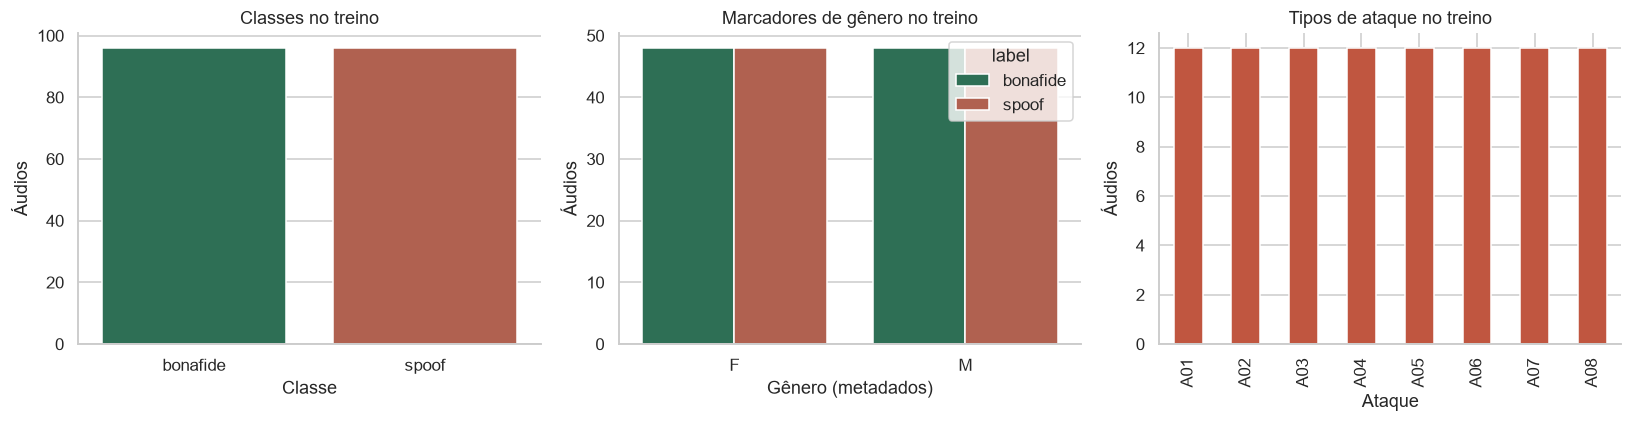

,Sistema,Descrição,F,M,Total
Ataque,,,,,
A01,Glow-TTS,Geração acústica por fluxos normalizantes; identidade vocal com ECAPA-TDNN.,6,6,12
A02,Glow-TTS (variante),"Como A01, mas representa a identidade vocal com ResNet-34.",6,6,12
A03,Glow-TTS (variante),"Como A01, mas representa a identidade vocal com TDNN Y-vector.",6,6,12
A04,Grad-TTS,Geração acústica por difusão; identidade vocal com ECAPA-TDNN.,6,6,12
A05,Grad-TTS (variante),"Como A04, mas representa a identidade vocal com ResNet-34.",6,6,12
A06,Grad-TTS (variante),"Como A04, mas representa a identidade vocal com TDNN Y-vector.",6,6,12
A07,FastPitch,Síntese com modelagem explícita da altura da voz (pitch).,6,6,12
A08,VITS,Síntese de ponta a ponta com inferência variacional e treinamento adversarial.,6,6,12


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=train, x='label', order=ORDER, hue='label', palette=PALETTE,
              legend=False, ax=axes[0])
axes[0].set(title='Classes no treino', xlabel='Classe', ylabel='Áudios')
sns.countplot(data=train, x='gender', hue='label', hue_order=ORDER,
              palette=PALETTE, ax=axes[1])
axes[1].set(title='Marcadores de gênero no treino', xlabel='Gênero (metadados)', ylabel='Áudios')
attacks = train.loc[train.label == 'spoof', 'attack'].value_counts().sort_index()
attacks.plot.bar(ax=axes[2], color=PALETTE['spoof'])
axes[2].set(title='Tipos de ataque no treino', xlabel='Ataque', ylabel='Áudios')
fig.tight_layout()
salvar_figura(fig, '01_composicao_treino')
# Apenas falsificações: bonafide não é um tipo de ataque.
attack_info = pd.DataFrame([
    ('A01', 'Glow-TTS', 'Geração acústica por fluxos normalizantes; identidade vocal com ECAPA-TDNN.'),
    ('A02', 'Glow-TTS (variante)', 'Como A01, mas representa a identidade vocal com ResNet-34.'),
    ('A03', 'Glow-TTS (variante)', 'Como A01, mas representa a identidade vocal com TDNN Y-vector.'),
    ('A04', 'Grad-TTS', 'Geração acústica por difusão; identidade vocal com ECAPA-TDNN.'),
    ('A05', 'Grad-TTS (variante)', 'Como A04, mas representa a identidade vocal com ResNet-34.'),
    ('A06', 'Grad-TTS (variante)', 'Como A04, mas representa a identidade vocal com TDNN Y-vector.'),
    ('A07', 'FastPitch', 'Síntese com modelagem explícita da altura da voz (pitch).'),
    ('A08', 'VITS', 'Síntese de ponta a ponta com inferência variacional e treinamento adversarial.'),
], columns=['Ataque', 'Sistema', 'Descrição']).set_index('Ataque')
spoof_train = train.loc[train['label'] == 'spoof']
attack_counts = pd.crosstab(spoof_train['attack'], spoof_train['gender']).reindex(
    index=attack_info.index, columns=['F', 'M'], fill_value=0)
attack_table = attack_info.join(attack_counts)
attack_table['Total'] = attack_table[['F', 'M']].sum(axis=1)
display(attack_table.style.set_properties(
    subset=['Descrição'], **{'white-space': 'normal', 'text-align': 'left', 'max-width': '440px'}))

**Anotações — composição**

- Podemos verificar que a composição está totalmente equilibrada em classe, genero e ataque

## 3. Duração e qualidade básica do sinal (treino)

Aqui medimos duração, pico, RMS global (amplitude efetiva) e proporção de amostras próximas dos limites ±1 (para avaliar saturação ou clipping).

O áudio é convertido para mono por média dos canais e reamostrado para 16 kHz, se necessário. Não cortamos silêncios nem normalizamos o volume: essas escolhas podem esconder diferenças que queremos investigar.

duration_s                                                            \
              count     mean     std     min     25%     50%      75%     max   
label                                                                           
bonafide       96.0  15.3081  2.9471  10.010  12.795  15.840  17.9125  19.950   
spoof          96.0  11.1757  2.7954   6.048   9.520  10.672  12.7160  18.272   

          peak          ... rms_global         near_clip_fraction            \
         count    mean  ...        75%     max              count mean  std   
label                   ...                                                   
bonafide  96.0  0.4260  ...     0.0493  0.0789               96.0  0.0  0.0   
spoof     96.0  0.3125  ...     0.0441  0.0694               96.0  0.0  0.0   

                                   
          min  25%  50%  75%  max  
label                              
bonafide  0.0  0.0  0.0  0.0  0.0  
spoof     0.0  0.0  0.0  0.0  0.0  

[2 rows x 32 columns]

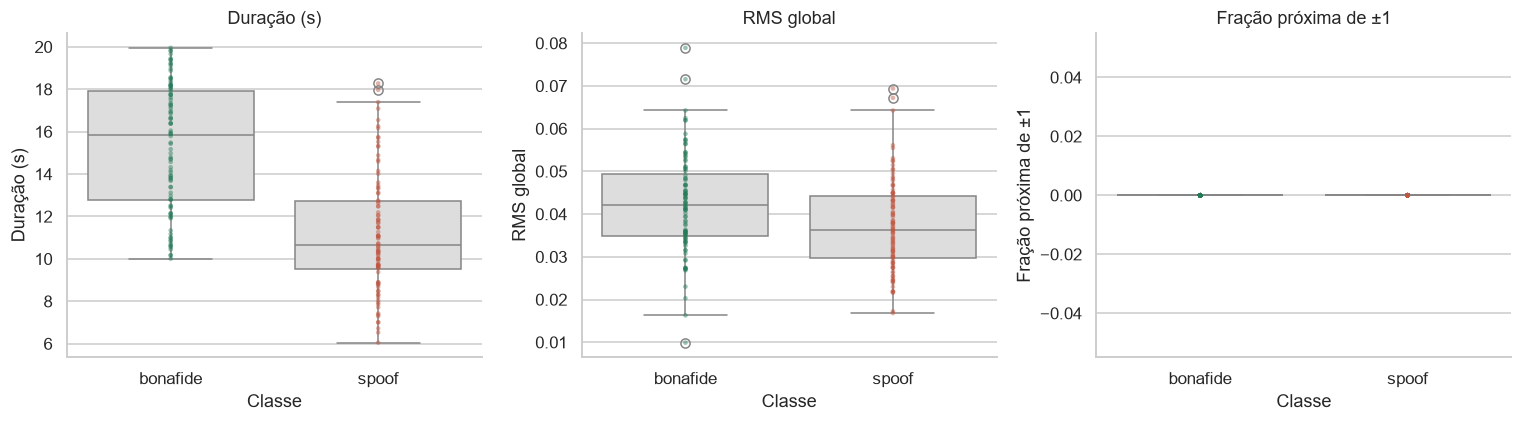

In [5]:
def carregar(file_id):
    rows = train.loc[train['file_id'] == file_id]
    if len(rows) != 1:
        raise ValueError('Escolha um file_id único do treinamento.')
    y, sr = sf.read(DATA / rows.iloc[0]['local_path'], dtype='float32', always_2d=True)
    y = y.mean(axis=1)
    if sr != CONFIG['sr']:
        y = librosa.resample(y, orig_sr=sr, target_sr=CONFIG['sr'])
    return y, CONFIG['sr']

quality_rows = []
for row in train.itertuples(index=False):
    y, sr = carregar(row.file_id)
    quality_rows.append({
        'file_id': row.file_id, 'duration_s': len(y) / sr,
        'peak': float(np.max(np.abs(y))),
        'rms_global': float(np.sqrt(np.mean(y.astype('float64') ** 2))),
        'near_clip_fraction': float(np.mean(np.abs(y) >= 0.999)),
    })
quality = train.merge(pd.DataFrame(quality_rows), on='file_id', validate='one_to_one')
display(quality.groupby('label')[['duration_s', 'peak', 'rms_global', 'near_clip_fraction']]
        .describe().round(4))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feature, title in zip(axes, ['duration_s', 'rms_global', 'near_clip_fraction'],
                            ['Duração (s)', 'RMS global', 'Fração próxima de ±1']):
    sns.boxplot(data=quality, x='label', y=feature, order=ORDER, ax=ax, color='#dddddd')
    sns.stripplot(data=quality, x='label', y=feature, order=ORDER, hue='label',
                  palette=PALETTE, jitter=False, alpha=.45, size=3, legend=False, ax=ax)
    ax.set(title=title, xlabel='Classe', ylabel=title)
fig.tight_layout()
salvar_figura(fig, '02_qualidade_treino')

**Anotações — duração**

- Podemos verificar que existe uma correlação entre duração e tipo de audio, com os bonafide sendo mais longos, com mediana de 16s, contra 11s dos falsos, embora exista bastante sobreposição entre as faixas. Essa associação sugere que a duração pode fornecer informação para classificação, mas também pode representar um viés do dataset, sem necessariamente generalizar para outros dados.

## 4. Ouvir e visualizar exemplos

Um exemplo de cada tipo de audio, para apreciação sonora.

O player usa `normalize=False` para preservar diferenças de amplitude. Use o controle do player para ouvir em volume confortável. Os exemplos não são um par do mesmo locutor nem do mesmo texto; diferenças podem vir da fala, gravação ou ataque.

**bonafide — T_0000096363 — ataque: bonafide**

**spoof — T_0000123477 — ataque: A07**

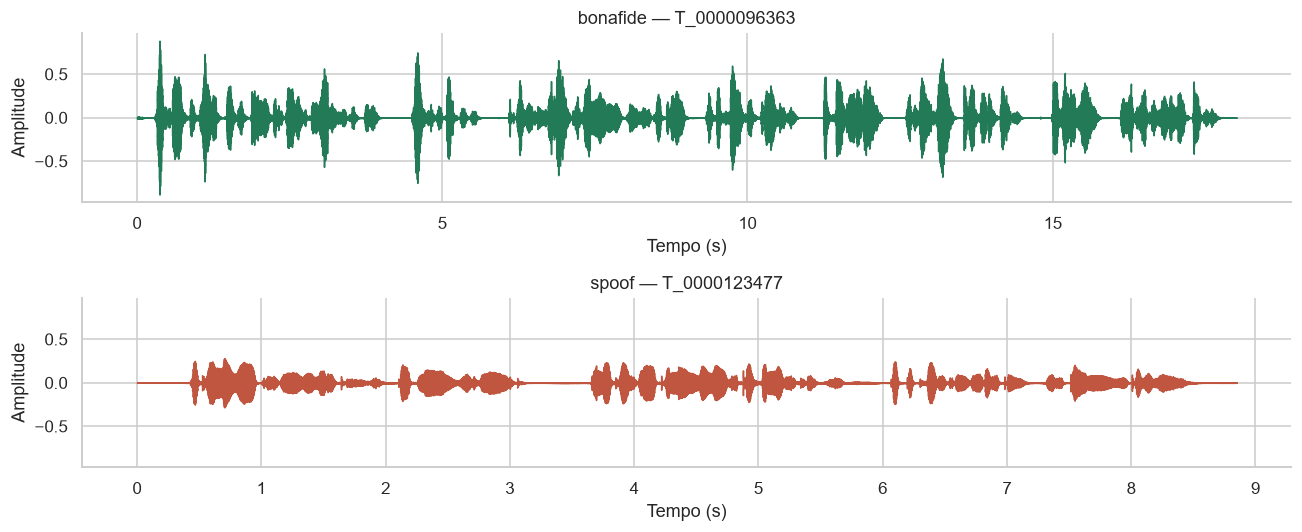

In [6]:
examples = {}
for label in ORDER:
    chosen_id = CONFIG[f'{label}_id']
    if chosen_id is None:
        chosen_id = train.loc[train.label == label].sample(random_state=CONFIG['seed']).iloc[0]['file_id']
    row = train.loc[train.file_id == chosen_id]
    if len(row) != 1 or row.iloc[0]['label'] != label:
        raise ValueError(f'{chosen_id}: escolha um ID de treino da classe {label}.')
    y, sr = carregar(chosen_id)
    examples[label] = (chosen_id, y, sr)
    display(Markdown(f"**{label} — {chosen_id} — ataque: {row.iloc[0]['attack']}**"))
    display(Audio(y, rate=sr, normalize=False))

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharey=True)
for ax, label in zip(axes, ORDER):
    file_id, y, sr = examples[label]
    librosa.display.waveshow(y, sr=sr, ax=ax, color=PALETTE[label])
    ax.set(title=f'{label} — {file_id}', xlabel='Tempo (s)', ylabel='Amplitude')
fig.tight_layout()
salvar_figura(fig, '03_formas_de_onda')

### Espectrograma Mel

A forma de onda mostra amplitude ao longo do tempo; o espectrograma mostra como a energia se distribui nas frequências. A escala Mel dá mais resolução às frequências baixas, de maneira inspirada na percepção auditiva.

As duas imagens usam a mesma referência e limites de cor (dB relativos à maior potência dos dois exemplos). Isso permite comparar energia sem normalizar cada figura separadamente. Uma imagem isolada não comprova que o áudio é falso.

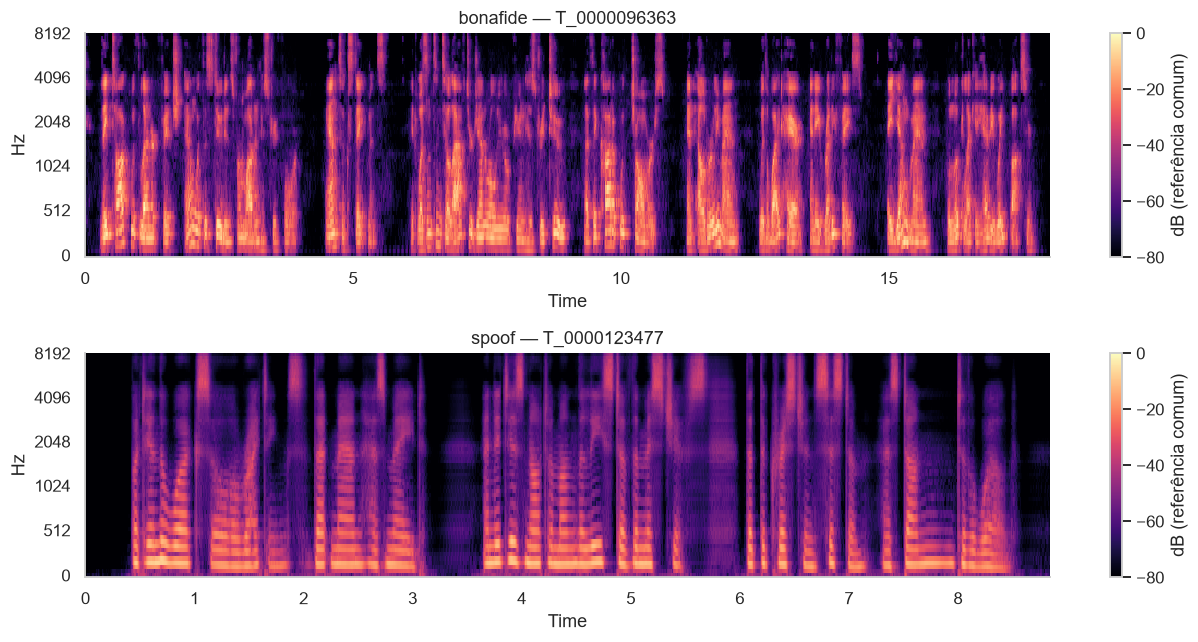

In [7]:
mels = {}
for label, (_, y, sr) in examples.items():
    mels[label] = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=CONFIG['n_fft'], hop_length=CONFIG['hop_length'],
        n_mels=CONFIG['n_mels'], power=2)
reference = max(float(s.max()) for s in mels.values())
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax, label in zip(axes, ORDER):
    db = librosa.power_to_db(mels[label], ref=max(reference, 1e-10), top_db=None)
    im = librosa.display.specshow(db, sr=CONFIG['sr'], hop_length=CONFIG['hop_length'],
             x_axis='time', y_axis='mel', ax=ax, vmin=-80, vmax=0, cmap='magma')
    ax.set_title(f'{label} — {examples[label][0]}')
    fig.colorbar(im, ax=ax, label='dB (referência comum)')
fig.tight_layout()
salvar_figura(fig, '04_espectrogramas_mel')

## 5. Extrair características acústicas do treino

Cada arquivo pode ter duração diferente. Calculamos atributos em janelas e resumimos cada sequência pela **média e desvio-padrão**, produzindo um vetor de tamanho fixo por áudio.

| Atributo | O que representa |
|---|---|
| RMS | Intensidade do sinal por janela |
| ZCR | Frequência de mudanças de sinal (cruzamentos por zero) |
| Centroide espectral | Centro de massa das magnitudes no espectro, em Hz |
| Largura espectral | Dispersão das magnitudes em torno do centroide, em Hz |
| Rolloff 85% | Frequência abaixo da qual estão 85% da soma das magnitudes |
| Planicidade espectral | Medida de quão plano é o espectro; valores maiores sugerem caráter ruidoso |
| MFCC 01–20 | Coeficientes que resumem o formato do espectro na escala Mel |


In [8]:
def extrair_atributos(y, sr):
    n_fft, hop = CONFIG['n_fft'], CONFIG['hop_length']
    magnitude = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop))
    mel = librosa.feature.melspectrogram(S=magnitude**2, sr=sr, n_mels=CONFIG['n_mels'])
    mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel), n_mfcc=CONFIG['n_mfcc'])
    rms = librosa.feature.rms(y=y, frame_length=n_fft, hop_length=hop)
    sequences = {
        'rms': rms,
        'zcr': librosa.feature.zero_crossing_rate(y, frame_length=n_fft, hop_length=hop),
        'centroid_hz': librosa.feature.spectral_centroid(S=magnitude, sr=sr),
        'bandwidth_hz': librosa.feature.spectral_bandwidth(S=magnitude, sr=sr),
        'rolloff_hz': librosa.feature.spectral_rolloff(S=magnitude, sr=sr, roll_percent=.85),
        'flatness': librosa.feature.spectral_flatness(S=magnitude),
    }
    features = {}
    for name, values in sequences.items():
        features[f'{name}_mean'] = float(values.mean())
        features[f'{name}_std'] = float(values.std(ddof=0))
    for i, values in enumerate(mfcc, start=1):
        features[f'mfcc_{i:02d}_mean'] = float(values.mean())
        features[f'mfcc_{i:02d}_std'] = float(values.std(ddof=0))
    features['low_energy_fraction'] = float(np.mean(rms < 10 ** (CONFIG['silence_dbfs'] / 20)))
    return features

feature_rows = []
for i, row in enumerate(train.itertuples(index=False), start=1):
    y, sr = carregar(row.file_id)
    feature_rows.append({'file_id': row.file_id, **extrair_atributos(y, sr)})
    if i % 48 == 0:
        print(f'Processados {i}/{len(train)} áudios de treino')
features = pd.DataFrame(feature_rows)
FEATURE_COLUMNS = [c for c in features.columns if c != 'file_id']
assert np.isfinite(features[FEATURE_COLUMNS].to_numpy()).all()
eda = quality.merge(features, on='file_id', validate='one_to_one')
display(eda[['file_id', 'label', *FEATURE_COLUMNS[:6]]].head())
print(f'{len(eda)} áudios; {len(FEATURE_COLUMNS)} atributos acústicos por áudio.')

Processados 48/192 áudios de treino
Processados 96/192 áudios de treino
Processados 144/192 áudios de treino
Processados 192/192 áudios de treino


,file_id,label,rms_mean,rms_std,zcr_mean,zcr_std,centroid_hz_mean,centroid_hz_std
0,T_0000007963,spoof,0.027082,0.020644,0.197284,0.184907,2251.964834,1180.208498
1,T_0000023159,spoof,0.029628,0.023494,0.140250,0.156469,1631.676799,1176.095383
2,T_0000062713,spoof,0.023549,0.018365,0.180531,0.186942,1981.884632,1301.123827
3,T_0000076071,spoof,0.015589,0.015321,0.160247,0.172215,1747.064461,1318.570315
4,T_0000099021,spoof,0.016491,0.014417,0.152637,0.180358,1639.944534,1398.276830


192 áudios; 53 atributos acústicos por áudio.


## 6. Comparar distribuições

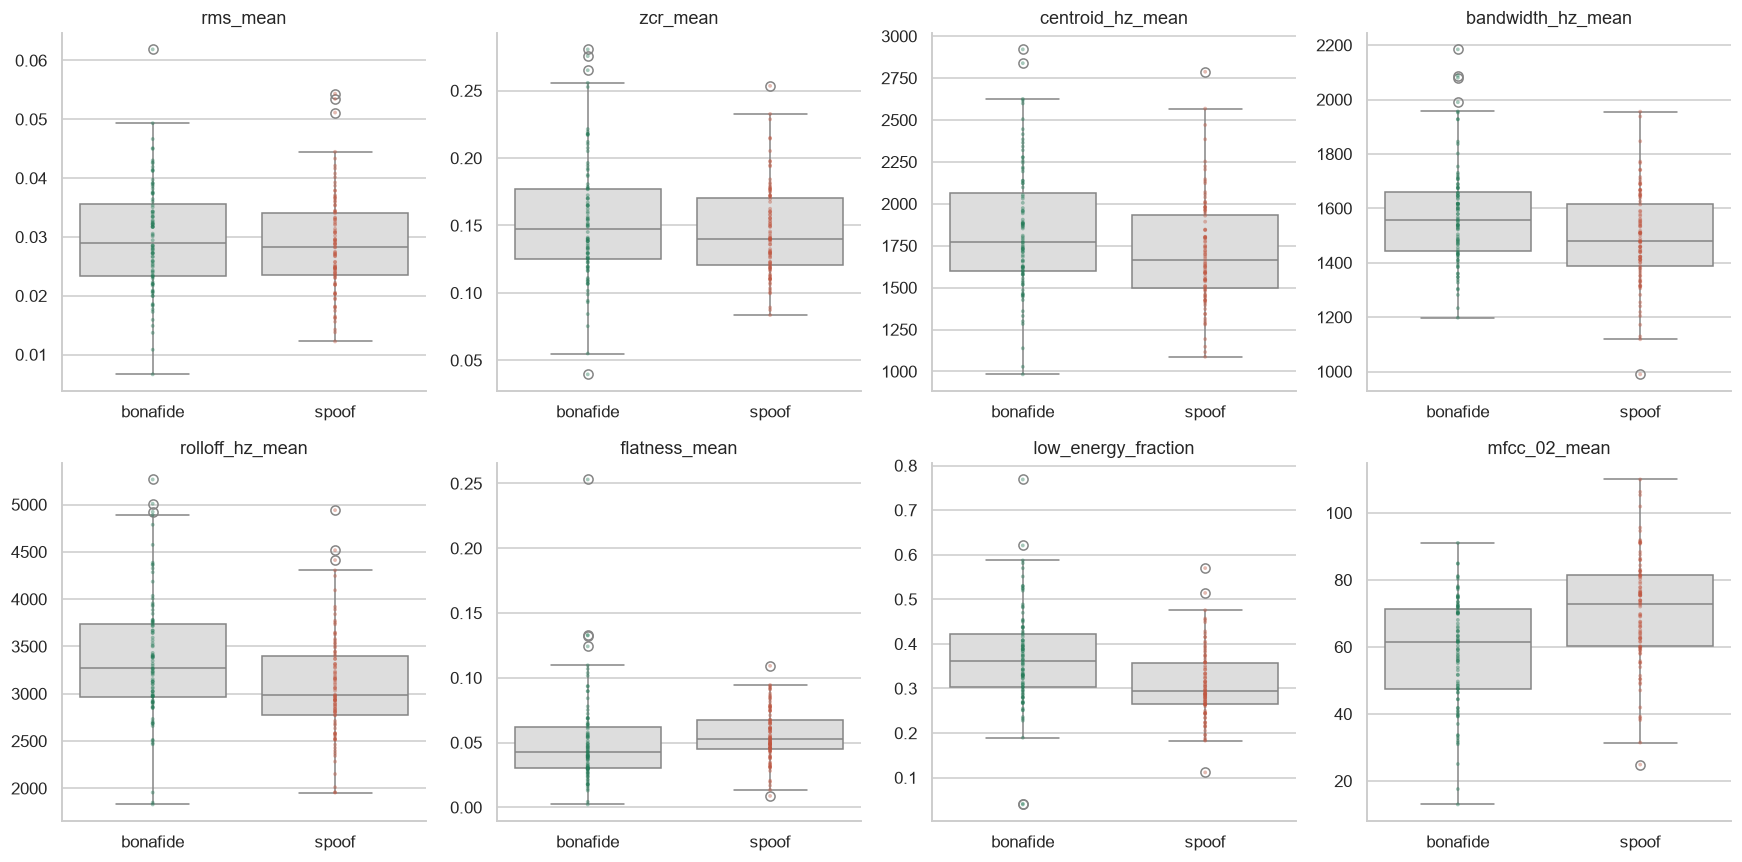

duration_s                 rms_mean                 zcr_mean          \
               mean     std  median     mean     std  median     mean     std   
label                                                                           
bonafide    15.3081  2.9471  15.840   0.0299  0.0091  0.0290   0.1533  0.0455   
spoof       11.1757  2.7954  10.672   0.0288  0.0084  0.0282   0.1460  0.0337   

                 centroid_hz_mean  ... rolloff_hz_mean flatness_mean          \
          median             mean  ...          median          mean     std   
label                              ...                                         
bonafide  0.1471        1843.9229  ...       3266.6960        0.0507  0.0343   
spoof     0.1402        1711.3278  ...       2987.3097        0.0559  0.0198   

                 low_energy_fraction                 mfcc_02_mean           \
          median                mean     std  median         mean      std   
label                                                                        
bonafide  0.0423              0.3689  0.1090  0.3614      58.5892  15.9046   
spoof     0.0524              0.3084  0.0775  0.2941      70.8008  16.2752   

                   
           median  
label              
bonafide  61.3668  
spoof     72.8010  

[2 rows x 27 columns]

In [9]:
selected = ['rms_mean', 'zcr_mean', 'centroid_hz_mean', 'bandwidth_hz_mean',
            'rolloff_hz_mean', 'flatness_mean', 'low_energy_fraction', 'mfcc_02_mean']
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, feature in zip(axes.flat, selected):
    sns.boxplot(data=eda, x='label', y=feature, order=ORDER, color='#dddddd', ax=ax)
    sns.stripplot(data=eda, x='label', y=feature, order=ORDER, hue='label',
                  palette=PALETTE, legend=False, alpha=.4, size=2.5, jitter=False, ax=ax)
    ax.set(title=feature, xlabel='', ylabel='')
fig.tight_layout()
salvar_figura(fig, '05_distribuicoes_atributos')
summary = eda.groupby('label')[['duration_s', *selected]].agg(['mean', 'std', 'median'])
display(summary.round(4))

### Perfil de MFCCs e correlações

O MFCC 01 corresponde ao coeficiente de ordem zero na saída do Librosa, bastante ligado à energia. Os demais descrevem outros aspectos do envelope espectral; não são frequências individuais.

O primeiro gráfico mostra a média entre arquivos dos MFCCs médios de cada classe. As barras representam **desvio-padrão entre arquivos**, não intervalo de confiança. A matriz de Spearman mostra associações entre atributos do treino; valores próximos de ±1 podem indicar informação redundante.

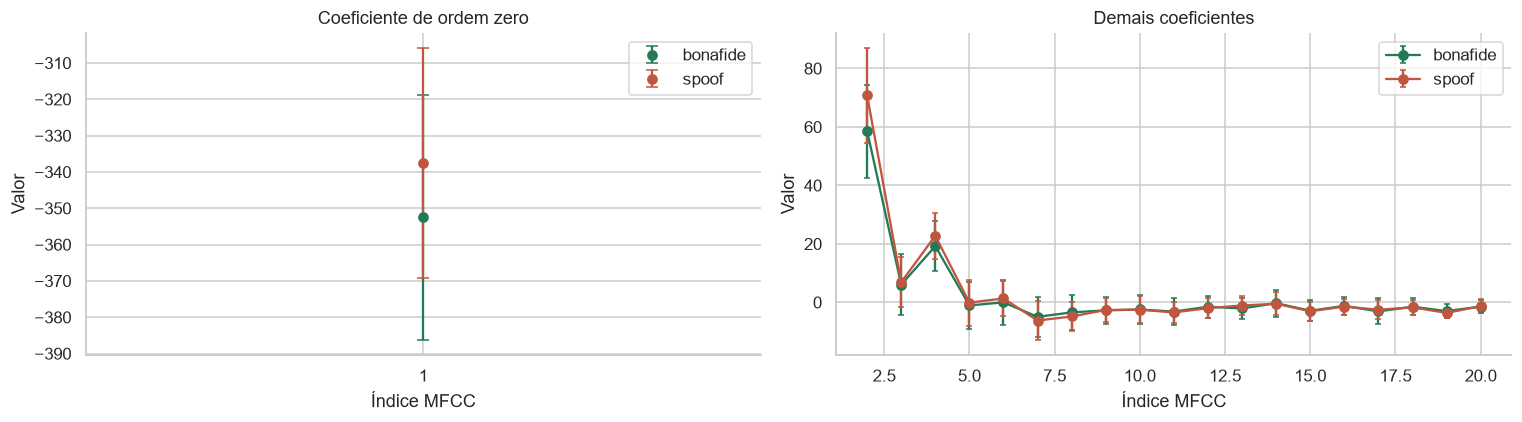

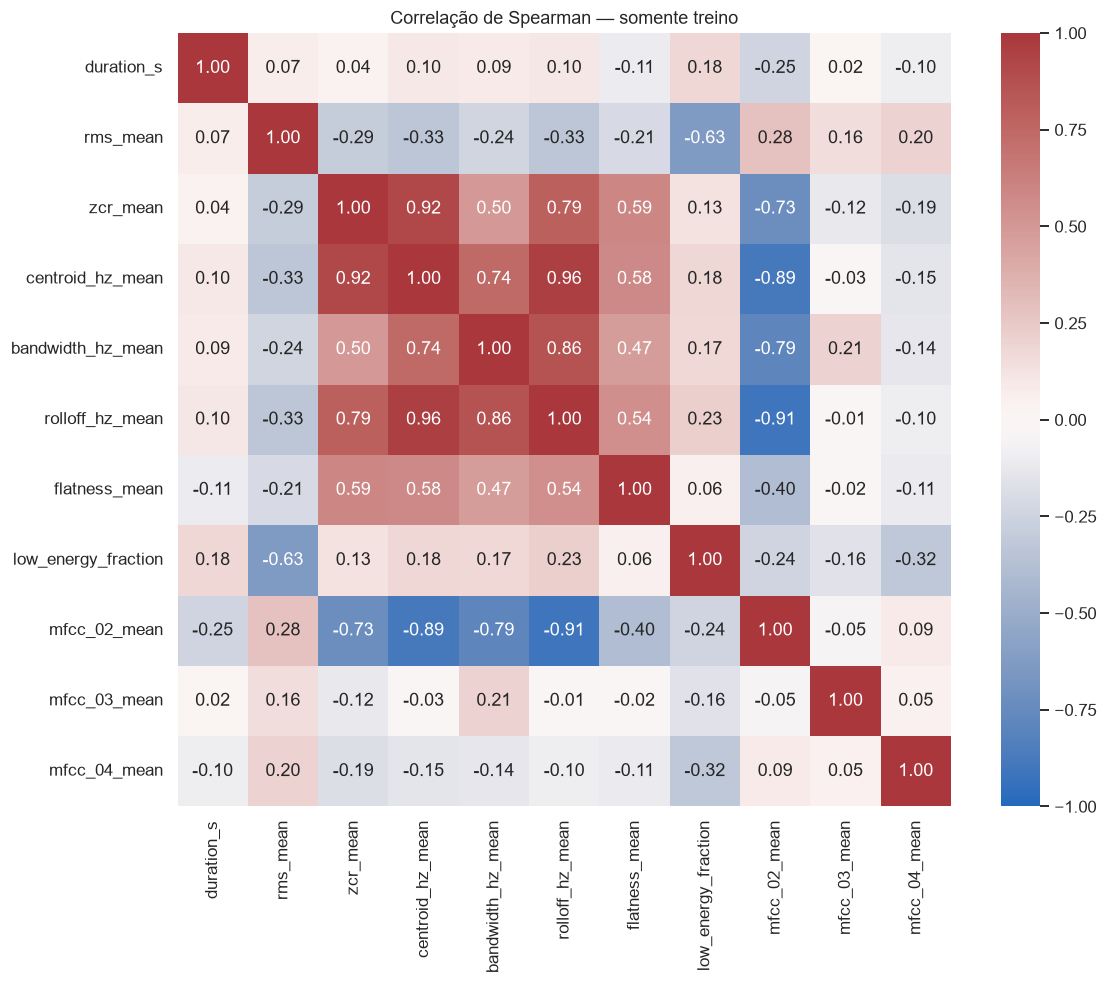

In [9]:
mfcc_means = [f'mfcc_{i:02d}_mean' for i in range(1, CONFIG['n_mfcc'] + 1)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for label in ORDER:
    values = eda.loc[eda.label == label, mfcc_means]
    axes[0].errorbar([1], [values.iloc[:, 0].mean()],
                     yerr=[values.iloc[:, 0].std()], fmt='o', capsize=4,
                     label=label, color=PALETTE[label])
    axes[1].errorbar(np.arange(2, CONFIG['n_mfcc'] + 1), values.iloc[:, 1:].mean(),
                     yerr=values.iloc[:, 1:].std(), marker='o', capsize=2,
                     label=label, color=PALETTE[label])
axes[0].set(title='Coeficiente de ordem zero', xlabel='Índice MFCC', ylabel='Valor')
axes[0].set_xticks([1])
axes[1].set(title='Demais coeficientes', xlabel='Índice MFCC', ylabel='Valor')
for ax in axes:
    ax.legend()
fig.tight_layout()
salvar_figura(fig, '06_perfil_mfcc')

corr_cols = ['duration_s', *selected, 'mfcc_03_mean', 'mfcc_04_mean']
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(eda[corr_cols].corr(method='spearman'), vmin=-1, vmax=1, center=0,
            cmap='vlag', annot=True, fmt='.2f', square=True, ax=ax)
ax.set_title('Correlação de Spearman — somente treino')
fig.tight_layout()
salvar_figura(fig, '07_correlacoes')

### Verificar possíveis fatores de confusão

Compare o mesmo atributo separando os marcadores de gênero e os tipos de ataque. Um efeito global pode ser causado por uma parte da amostra. Mesmo com equilíbrio F/M, outras características de fala e gravação podem interferir. Como os locutores não se repetem, não temos pares do mesmo locutor para isolar o efeito da falsificação.

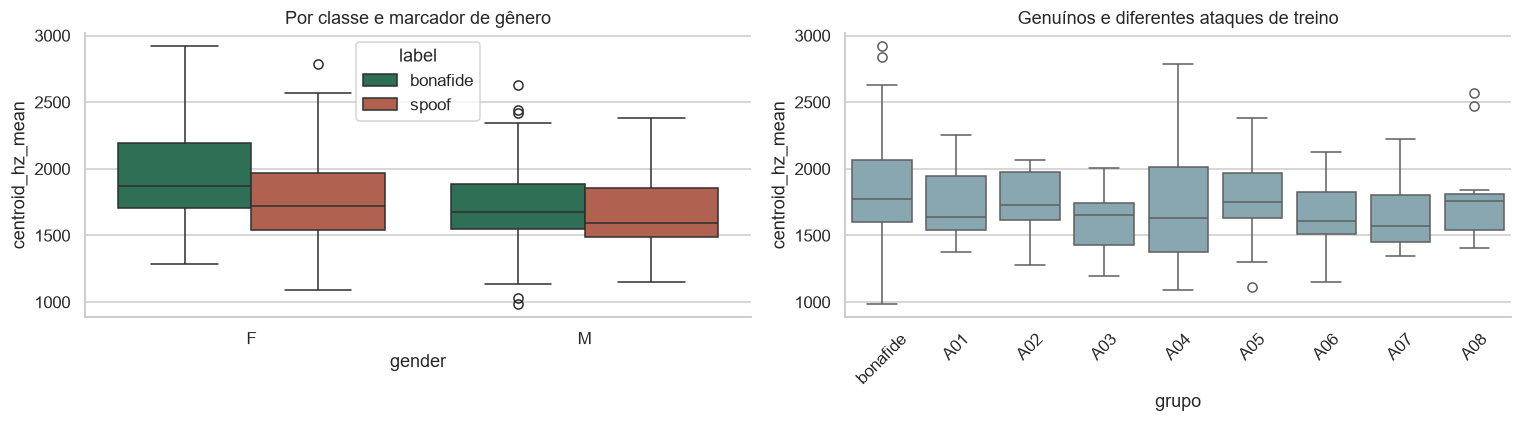

In [11]:
# Altere para outro atributo presente em FEATURE_COLUMNS.
ATRIBUTO = 'centroid_hz_mean'
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=eda, x='gender', y=ATRIBUTO, hue='label', hue_order=ORDER,
            palette=PALETTE, ax=axes[0])
axes[0].set_title('Por classe e marcador de gênero')
by_attack = eda.assign(grupo=np.where(eda.label == 'bonafide', 'bonafide', eda.attack))
groups = ['bonafide', *sorted(eda.loc[eda.label == 'spoof', 'attack'].unique())]
sns.boxplot(data=by_attack, x='grupo', y=ATRIBUTO, order=groups,
            color='#82aab7', ax=axes[1])
axes[1].set_title('Genuínos e diferentes ataques de treino')
axes[1].tick_params(axis='x', rotation=45)
fig.tight_layout()
salvar_figura(fig, '08_fatores_de_confusao')

## 7. Exportar evidências e registrar a execução

O CSV de atributos contém apenas `file_id` como chave e as medidas acústicas; rótulos e metadados ficam em tabela separada. No futuro, selecione explicitamente os atributos da lista exportada e exclua `file_id` da entrada do modelo. Qualquer padronização ou seleção de atributos deverá ser ajustada somente nas dobras de treino da validação cruzada.

As exportações são refeitas a cada execução. Para comparar configurações, copie os resultados para uma pasta identificada antes de alterar a CONFIG.

In [13]:
features.to_csv(OUT / 'atributos_treino.csv', index=False)
train.to_csv(OUT / 'metadados_treino.csv', index=False)
quality[['file_id', 'duration_s', 'peak', 'rms_global', 'near_clip_fraction']].to_csv(
    OUT / 'qualidade_treino.csv', index=False)
summary.to_csv(OUT / 'resumo_por_classe.csv')
packages = ['librosa', 'soundfile', 'numpy', 'pandas', 'matplotlib', 'seaborn',
            'scipy', 'numba', 'scikit-learn', 'ipykernel', 'nbformat', 'nbclient']
manifest = {
    'executed_at_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'platform': platform.platform(),
    'config': CONFIG, 'packages': {p: version(p) for p in packages},
    'train_rows': len(train), 'test_rows_integrity_only': len(test),
    'feature_columns': FEATURE_COLUMNS,
    'examples': {k: v[0] for k, v in examples.items()},
    'input_csv_sha256': {name: hashlib.sha256((DATA / name).read_bytes()).hexdigest()
                         for name in ['treino_192.csv', 'teste_96.csv']},
}
(OUT / 'execucao.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
print('Tabelas e configuração:', OUT)
print('Figuras:', FIG)
print('Salve o notebook para preservar suas saídas e anotações.')

Tabelas e configuração: d:\Code\portfolio-pcs5917\outros\aula-03-deteccao-audio-falso\resultados\eda
Figuras: d:\Code\portfolio-pcs5917\images\aula-03\eda
Salve o notebook para preservar suas saídas e anotações.


## 8. Análise

1. **Dados:** composição bem equilibrada.
2. **Escuta:** é perceptível para o ouvido humano distinguir a maior parte dos áudios sintéticos
3. **Atributos:** duração tem uma correlação com o tipo de áudio, embora exista bastante sobreposição
4. **Confundidores:** existe uma distribuição aleatória aceitável entre os diversos atributos de áudio.

Embora a seleção seja balanceada por classe, gênero e ataque, existem diferenças nas distribuições de duração, baixa energia e alguns atributos espectrais. Há sobreposição considerável entre as classes e forte correlação entre parte dos atributos. Esses padrões motivam experimentos de classificação, mas podem refletir características da seleção e dos geradores, sem garantir generalização para métodos desconhecidos.

## Referências

- [Dataset ASVspoof no Kaggle](https://www.kaggle.com/datasets/ulianazb/asvspoof-2024) — origem dos arquivos e metadados selecionados.
- [Seleção local e protocolo experimental](../outros/aula-03-deteccao-audio-falso/dados/subconjunto_288/README.md).
- [Documentação Librosa 0.11.0: atributos](https://librosa.org/doc/0.11.0/feature.html).
- [MFCCs no Librosa](https://librosa.org/doc/0.11.0/generated/librosa.feature.mfcc.html).
- [SoundFile: leitura de áudio](https://python-soundfile.readthedocs.io/).